# **EN3160 Image Processing & Computer Vision - Assignment 03**


**Name : Meedeniya M.M.H**  
**Index No. : 230407K**

### **Github Repository** : https://github.com/manjarimeedeniya/EN3160-Assignment3

## Question 1 

In this task we turn a basic linear classifier into a two layer network by adding a hidden layer with sigmoid activation and cross entropy loss. We derive and code the forward and backward passes completely by hand in PyTorch to train and evaluate on CIFAR 10.

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [ ]:
# Transform and normalize images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Batch size
batch_size = 50

# Training dataset
trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)
# Test dataset
testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

print("Training images:", len(trainset))
print("Test images:", len(testset))

Training images: 50000
Test images: 10000


In [ ]:
Din = 3 * 32 * 32   # 3072 input features
H = 100             # 100 hidden neurons
K = 10              # 10 output classes

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
std = 1e-5
W1 = (torch.randn(Din, H) * std).to(device)
b1 = torch.zeros(H, device=device)
W2 = (torch.randn(H, K) * std).to(device)
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10
lr = 0.1
lr_decay = 0.9
# Store results
loss_history = []
train_acc_history = []
test_acc_history = []

print("Device:", device)


Device: cpu


In [ ]:
# Training loop with loss and accuracy tracking
loss_history = []
train_acc_history = []
test_acc_history = []

for epoch in range(epochs):
    # Training
    running_loss = 0.0
    total_samples = 0
    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        N = inputs.shape[0]
        x = inputs.reshape(N, -1)

        # Forward pass: hidden layer
        z1 = x.mm(W1) + b1
        h = torch.sigmoid(z1)
        logits = h.mm(W2) + b2

        # Cross-entropy loss
        log_probs = torch.log_softmax(logits, dim=1)
        loss = -log_probs[
            torch.arange(N, device=device), labels
        ].mean()
        running_loss += loss.item() * N
        total_samples += N

        # Backpropagation: output layer
        probs = torch.softmax(logits, dim=1)
        dlogits = probs.clone()
        dlogits[
            torch.arange(N, device=device), labels
        ] -= 1
        dlogits /= N
        dW2 = h.t().mm(dlogits)
        db2 = dlogits.sum(dim=0)

        # Backpropagation: hidden layer
        dh = dlogits.mm(W2.t())
        dz1 = dh * h * (1 - h)
        dW1 = x.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Update weights and biases
        with torch.no_grad():
            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

    # Record average loss
    epoch_loss = running_loss / total_samples
    loss_history.append(epoch_loss)

    #Training accuracy
    correct_train = 0
    total_train = 0

    with torch.no_grad():
        for inputs, labels in trainloader:

            inputs = inputs.to(device)
            labels = labels.to(device)
            x = inputs.reshape(inputs.shape[0], -1)
            h = torch.sigmoid(x.mm(W1) + b1)
            logits = h.mm(W2) + b2
            predictions = logits.argmax(dim=1)
            correct_train += (
                predictions == labels
            ).sum().item()
            total_train += labels.size(0)

    train_acc = 100 * correct_train / total_train
    train_acc_history.append(train_acc)

    # Test accuracy
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            x = inputs.reshape(inputs.shape[0], -1)
            h = torch.sigmoid(x.mm(W1) + b1)
            logits = h.mm(W2) + b2
            predictions = logits.argmax(dim=1)
            correct_test += (
                predictions == labels
            ).sum().item()
            total_test += labels.size(0)

    test_acc = 100 * correct_test / total_test
    test_acc_history.append(test_acc)

    # Display this epoch's results
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10 | Loss: 1.4484 | Train Accuracy: 51.15% | Test Accuracy: 47.72%
Epoch 2/10 | Loss: 1.4308 | Train Accuracy: 51.50% | Test Accuracy: 47.81%
Epoch 3/10 | Loss: 1.4147 | Train Accuracy: 52.29% | Test Accuracy: 47.97%
Epoch 4/10 | Loss: 1.4002 | Train Accuracy: 52.42% | Test Accuracy: 48.19%
Epoch 5/10 | Loss: 1.3878 | Train Accuracy: 53.11% | Test Accuracy: 48.48%
Epoch 6/10 | Loss: 1.3757 | Train Accuracy: 53.21% | Test Accuracy: 48.52%
Epoch 7/10 | Loss: 1.3659 | Train Accuracy: 53.93% | Test Accuracy: 48.87%
Epoch 8/10 | Loss: 1.3555 | Train Accuracy: 54.18% | Test Accuracy: 48.76%
Epoch 9/10 | Loss: 1.3474 | Train Accuracy: 54.39% | Test Accuracy: 48.80%
Epoch 10/10 | Loss: 1.3394 | Train Accuracy: 54.64% | Test Accuracy: 49.07%



Final 10-Epoch Results:
Training Accuracy: 54.64%
Test Accuracy:     49.07%


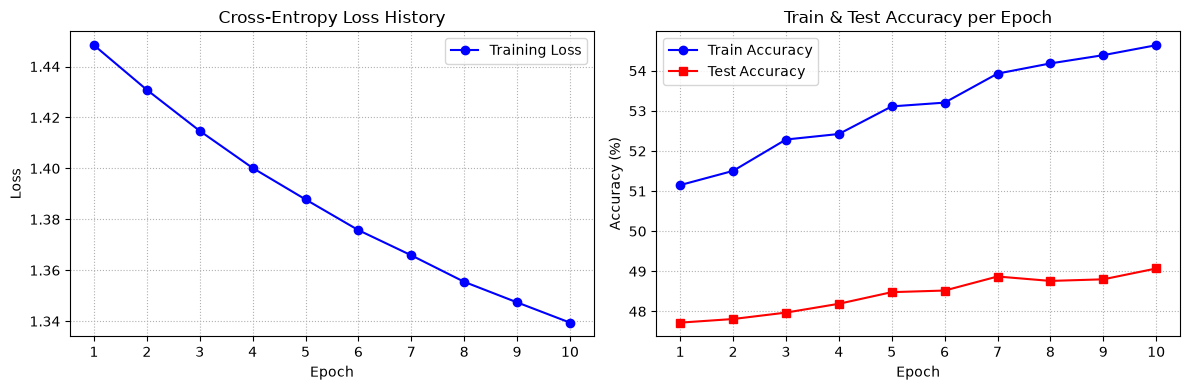

In [ ]:
# Final Accuracy & Loss History Plot
print("\nFinal 10-Epoch Results:")
print(f"Training Accuracy: {train_acc_history[-1]:.2f}%")
print(f"Test Accuracy:     {test_acc_history[-1]:.2f}%")
plt.figure(figsize=(12, 4))
# Loss history
plt.subplot(1, 2, 1)
plt.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    'b-o',
    label='Training Loss'
)
plt.title("Cross-Entropy Loss History")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle=':')
plt.legend()

# Accuracy history
plt.subplot(1, 2, 2)
plt.plot(
    range(1, len(train_acc_history) + 1),
    train_acc_history,
    'b-o',
    label='Train Accuracy'
)
plt.plot(
    range(1, len(test_acc_history) + 1),
    test_acc_history,
    'r-s',
    label='Test Accuracy'
)
plt.title("Train & Test Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle=':')
plt.legend()

plt.tight_layout()
plt.show()


### Discussion  
* Looking at the results, the training loss dropped smoothly from 1.45 to 1.34 over the 10 epochs. This indicates that the model was learning to make better predictions as training progressed.The training accuracy went from 51.15% to 54.64%.  
* The test accuracy also showed some improvement, starting at 47.72% and reaching a peak of 49.07%. So can obsereve its performance on unseen images remained relatively limited.  The test accuracy began to level off around the seventh epoch.
* The gap between training and testing was only around 5.5%, so there was no noticeable overfitting. 
* Since the images are flattened into one-dimensional vectors, the network cannot directly take advantage of the spatial relationships.if  convolutional neural network is used, it can learn spatial features such as edges, shapes, and textures.
* Overall, this demonstrates how a hidden layer, an activation function, and cross-entropy loss can be used to build a neural network for image classification. However, the results also highlight the limitations of a simple fully connected network when working with image data.

## Question 2

Here we build and compare the classic LeNet 5 architecture against a modern three layer CNN featuring batch normalization, ReLU, and dropout. We train both on MNIST under identical setups to analyze

### 2(a)

In [ ]:
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# LeNet-5 needs 32x32: Pad MNIST (28x28) with 2 pixels on each side
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64
epochs = 10
learning_rate = 0.001

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.features = nn.Sequential(
            # C1: Input (1, 32, 32) -> Output (6, 28, 28)
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1),
            nn.Tanh(),
            # S2: Output (6, 14, 14)
            nn.AvgPool2d(kernel_size=2, stride=2),
            # C3: Output (16, 10, 10)
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1),
            nn.Tanh(),
            # S4: Output (16, 5, 5)
            nn.AvgPool2d(kernel_size=2, stride=2),
            # C5: Output (120, 1, 1)
            nn.Conv2d(in_channels=16, out_channels=120, kernel_size=5, stride=1),
            nn.Tanh()
        )
        self.classifier = nn.Sequential(
            # F6: Linear mapping from 120 -> 84
            nn.Linear(120, 84),
            nn.Tanh(),
            # Output: 84 -> 10 classes
            nn.Linear(84, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1) 
        logits = self.classifier(x)
        return logits

model = LeNet5().to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []

for epoch in range(epochs):
    #Training Phase
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, targets in trainloader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total_train += targets.size(0)
        correct_train += (preds == targets).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100.0 * correct_train / total_train

    # Testing Phase
    model.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in testloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total_test += targets.size(0)
            correct_test += (preds == targets).sum().item()

    epoch_test_loss = test_loss / total_test
    epoch_test_acc = 100.0 * correct_test / total_test
    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_test_loss)
    train_accuracies.append(epoch_train_acc)
    test_accuracies.append(epoch_test_acc)

    print(f"Epoch {epoch+1:02d}/10 | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}%")
print(f"\nFinal Result after 10 epochs:")
print(f"Training Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Test Accuracy:     {test_accuracies[-1]:.2f}%")

Using device: cpu
LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (classifier): Sequential(
    (0): Linear(in_features=120, out_features=84, bias=True)
    (1): Tanh()
    (2): Linear(in_features=84, out_features=10, bias=True)
  )
)
Epoch 01/10 | Train Loss: 0.2412 | Train Acc: 93.20% | Test Loss: 0.0861 | Test Acc: 97.31%
Epoch 02/10 | Train Loss: 0.0692 | Train Acc: 97.86% | Test Loss: 0.0520 | Test Acc: 98.35%
Epoch 03/10 | Train Loss: 0.0512 | Train Acc: 98.44% | Test Loss: 0.0466 | Test Acc: 98.51%
Epoch 04/10 | Train Loss: 0.0395 | Train Acc: 98.76% | Test Loss: 0.0461 | Test Acc: 98.57%
Epoch 05/10 | Train Loss: 0.0325 | Train Acc: 99.02% | Test Loss: 0.0486

### 2(b)

In [ ]:
transform_modern = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64
epochs = 10
learning_rate = 0.001

trainset_modern = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_modern)
testset_modern  = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_modern)
trainloader_modern = torch.utils.data.DataLoader(trainset_modern, batch_size=batch_size, shuffle=True, num_workers=2)
testloader_modern  = torch.utils.data.DataLoader(testset_modern, batch_size=batch_size, shuffle=False, num_workers=2)

# Modern 3-Layer CNN Architecture
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()
        self.features = nn.Sequential(
            # Conv Layer 1: (1, 28, 28) -> (32, 28, 28) -> MaxPool -> (32, 14, 14)
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.1),

            # Conv Layer 2: (32, 14, 14) -> (64, 14, 14) -> MaxPool -> (64, 7, 7)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.2),

            # Conv Layer 3: (64, 7, 7) -> (128, 5, 5)
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=0),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout2d(0.25)
        )
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        logits = self.classifier(x)
        return logits

modern_model = ModernCNN().to(device)
print(modern_model)

# Training Loop under Identical Conditions
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modern_model.parameters(), lr=learning_rate)

modern_train_losses, modern_test_losses = [], []
modern_train_accuracies, modern_test_accuracies = [], []

print("\nTraining Modern CNN (10 Epochs)")
for epoch in range(epochs):
    # Training
    modern_model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, targets in trainloader_modern:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = modern_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total_train += targets.size(0)
        correct_train += (preds == targets).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100.0 * correct_train / total_train

    # Testing
    modern_model.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in testloader_modern:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = modern_model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total_test += targets.size(0)
            correct_test += (preds == targets).sum().item()

    epoch_test_loss = test_loss / total_test
    epoch_test_acc = 100.0 * correct_test / total_test

    modern_train_losses.append(epoch_train_loss)
    modern_test_losses.append(epoch_test_loss)
    modern_train_accuracies.append(epoch_train_acc)
    modern_test_accuracies.append(epoch_test_acc)

    print(f"Epoch {epoch+1:02d}/10 | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}%")

print(f"\nFinal Modern CNN Result after 10 epochs:")
print(f"Training Accuracy: {modern_train_accuracies[-1]:.2f}%")
print(f"Test Accuracy:     {modern_test_accuracies[-1]:.2f}%")

ModernCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.1, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): Dropout2d(p=0.25, inplace=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Linear(in_f

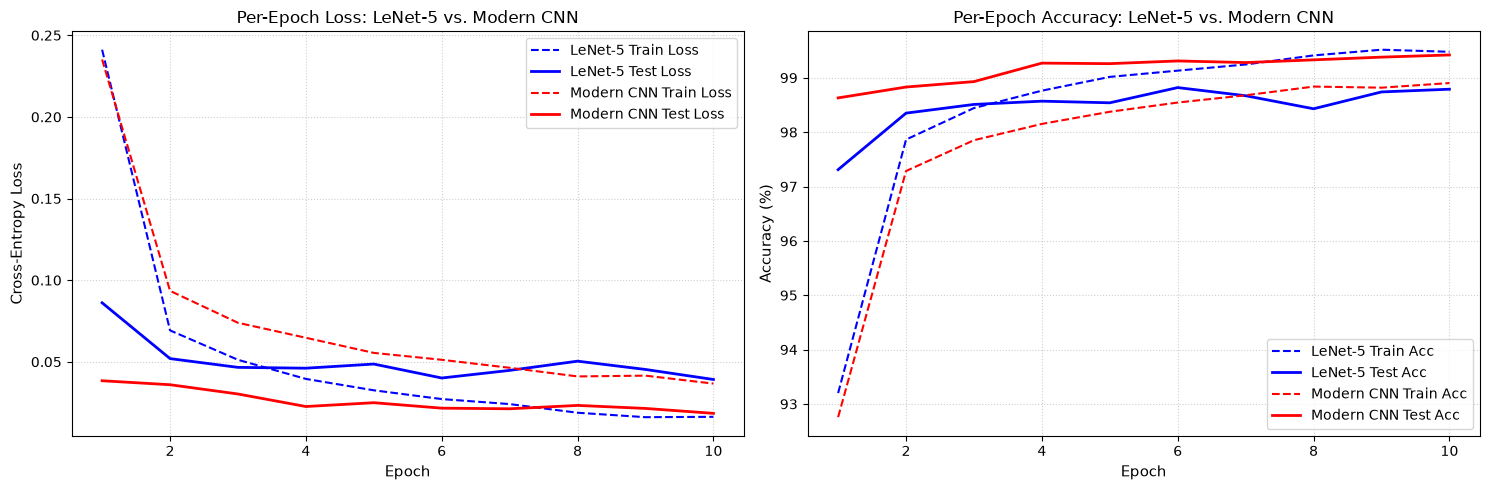

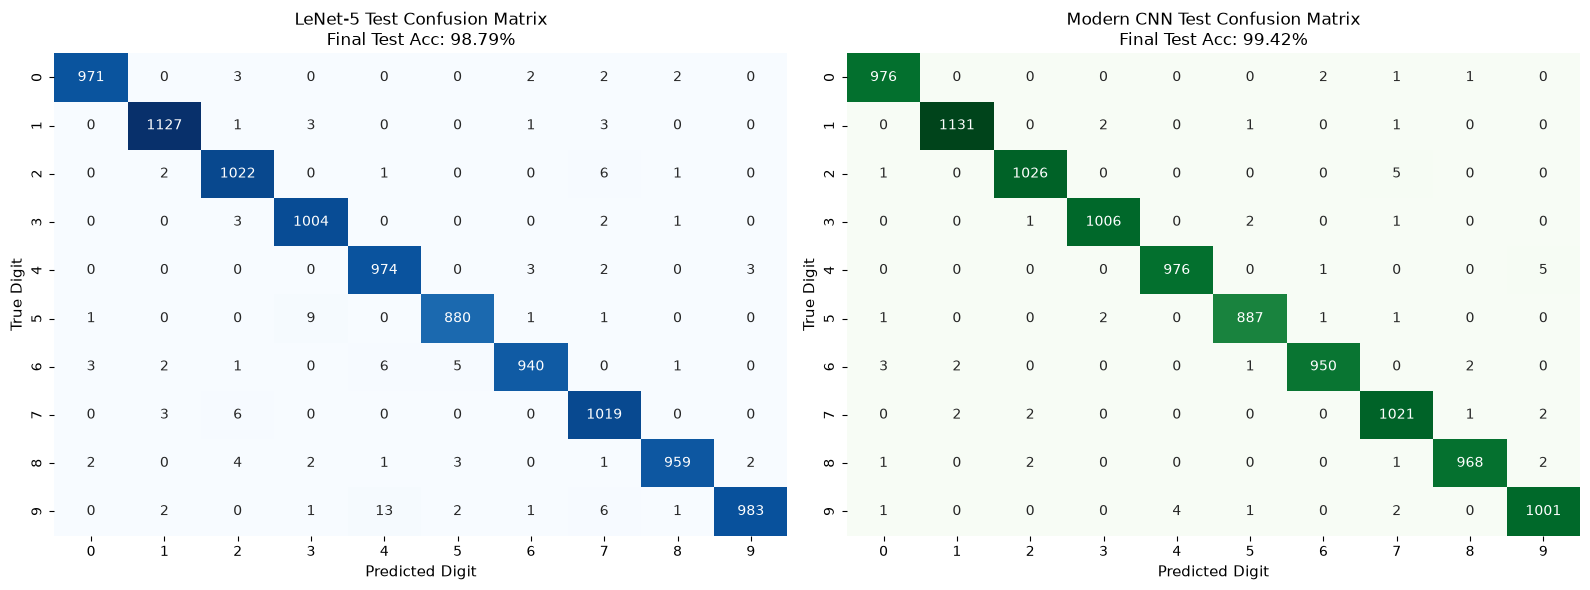

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def extract_predictions(model, dataloader):
    model.eval()
    all_targets = []
    all_predictions = []
    
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_predictions.extend(preds.cpu().numpy())
            all_targets.extend(targets.numpy())
            
    return np.array(all_targets), np.array(all_predictions)

y_true_lenet, y_pred_lenet = extract_predictions(model, testloader)
y_true_modern, y_pred_modern = extract_predictions(modern_model, testloader_modern)

epochs_range = range(1, len(train_losses) + 1)
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, 'b--', label='LeNet-5 Train Loss')
plt.plot(epochs_range, test_losses, 'b-', linewidth=2, label='LeNet-5 Test Loss')
plt.plot(epochs_range, modern_train_losses, 'r--', label='Modern CNN Train Loss')
plt.plot(epochs_range, modern_test_losses, 'r-', linewidth=2, label='Modern CNN Test Loss')
plt.title('Per-Epoch Loss: LeNet-5 vs. Modern CNN', fontsize=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Cross-Entropy Loss', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, 'b--', label='LeNet-5 Train Acc')
plt.plot(epochs_range, test_accuracies, 'b-', linewidth=2, label='LeNet-5 Test Acc')
plt.plot(epochs_range, modern_train_accuracies, 'r--', label='Modern CNN Train Acc')
plt.plot(epochs_range, modern_test_accuracies, 'r-', linewidth=2, label='Modern CNN Test Acc')
plt.title('Per-Epoch Accuracy: LeNet-5 vs. Modern CNN', fontsize=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

cm_lenet = confusion_matrix(y_true_lenet, y_pred_lenet)
cm_modern = confusion_matrix(y_true_modern, y_pred_modern)
class_names = [str(i) for i in range(10)]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# LeNet-5 Matrix
sns.heatmap(
    cm_lenet, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=class_names, 
    yticklabels=class_names, 
    ax=axes[0], 
    cbar=False
)
axes[0].set_title(f'LeNet-5 Test Confusion Matrix\nFinal Test Acc: {test_accuracies[-1]:.2f}%', fontsize=12)
axes[0].set_xlabel('Predicted Digit', fontsize=11)
axes[0].set_ylabel('True Digit', fontsize=11)

# Modern CNN Matrix
sns.heatmap(
    cm_modern, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    xticklabels=class_names, 
    yticklabels=class_names, 
    ax=axes[1], 
    cbar=False
)
axes[1].set_title(f'Modern CNN Test Confusion Matrix\nFinal Test Acc: {modern_test_accuracies[-1]:.2f}%', fontsize=12)
axes[1].set_xlabel('Predicted Digit', fontsize=11)
axes[1].set_ylabel('True Digit', fontsize=11)
plt.tight_layout()
plt.show()

### Discussion
* Both models did well. However, the Modern CNN clearly came out ahead with a test accuracy of 99.42% over LeNet-5's 98.79%.  
* According to the graphs the Modern CNN starts with high test accuracy and holding a steady, low test loss the entire time.  
* But LeNet-5's training accuracy kept climbing. But its test loss started creeping up after epoch 6.  
* From confusion matrices can see that how the Modern CNN reduced common mix-ups.

### Visual Results

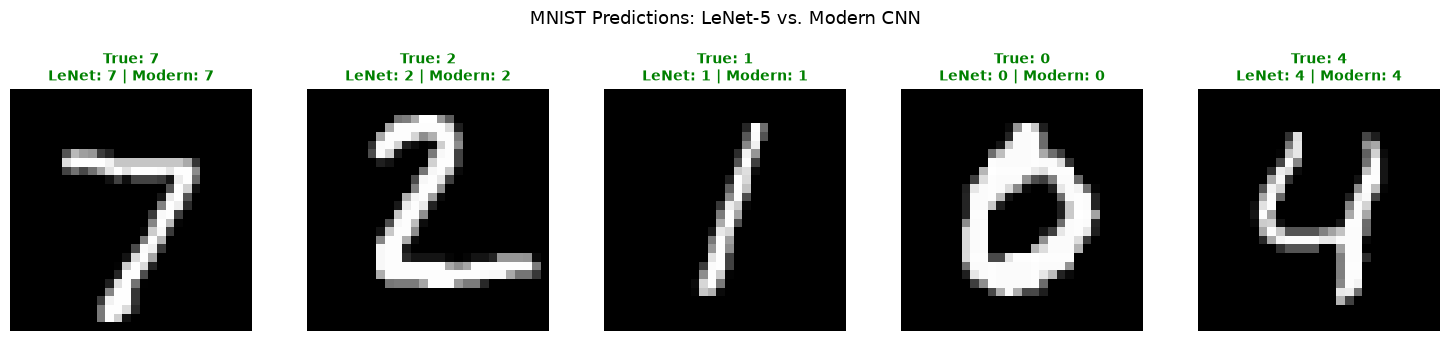

In [ ]:
import torch.nn.functional as F

def visualize_q2_horizontal(lenet_net, modern_net, testloader, num_images=5):
    lenet_net.eval()
    modern_net.eval()

    # Fetching a batch of test data
    dataiter = iter(testloader)
    images, labels = next(dataiter)

    # Move raw images to the configured device
    images_raw = images.to(device)

    images_padded = F.pad(images_raw, (2, 2, 2, 2), mode='constant', value=0)
    with torch.no_grad():
        preds_lenet = torch.argmax(lenet_net(images_padded), dim=1).cpu()
        preds_modern = torch.argmax(modern_net(images_raw), dim=1).cpu()

    fig, axes = plt.subplots(1, num_images, figsize=(15, 3.2))
    for idx in range(num_images):
        ax = axes[idx]
        ax.axis('off')
        img = images[idx].squeeze().cpu().numpy() * 0.3081 + 0.1307
        img = np.clip(img, 0, 1)

        l_ok = (preds_lenet[idx] == labels[idx])
        m_ok = (preds_modern[idx] == labels[idx])
        title_color = 'green' if (l_ok and m_ok) else ('darkorange' if (l_ok or m_ok) else 'red')

        title_str = (
            f"True: {labels[idx].item()}\n"
            f"LeNet: {preds_lenet[idx].item()} | Modern: {preds_modern[idx].item()}"
        )

        ax.set_title(title_str, color=title_color, fontsize=10, fontweight='bold')
        ax.imshow(img, cmap='gray')

    plt.suptitle("MNIST Predictions: LeNet-5 vs. Modern CNN", fontsize=13, y=1.05)
    plt.tight_layout()
    plt.show()

visualize_q2_horizontal(model, modern_model, testloader_modern, num_images=5)

## Question 3: Transfer Learning for Insect Classification using ResNet 18

In this final task we take an ImageNet pretrained ResNet 18 and apply it to a small dataset of ants and bees using transfer learning. We test both full network fine tuning and frozen feature extraction.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
import time
import os
import copy
import urllib.request
import zipfile

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
dataset_url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
zip_path = "hymenoptera_data.zip"
data_dir = "hymenoptera_data"

if not os.path.exists(data_dir):
    urllib.request.urlretrieve(dataset_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=2) for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print(f"Classes: {class_names}")
print(f"Training images: {dataset_sizes['train']} | Validation images: {dataset_sizes['val']}")

Classes: ['ants', 'bees']
Training images: 244 | Validation images: 153


In [ ]:
# Now I will perform training
def train_model(model, criterion, optimizer, scheduler, num_epochs=15):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1:02d}/{num_epochs}")
        print("-" * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()
            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train' and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item() * 100)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc*100:.2f}%")

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Val Accuracy: {best_acc*100:.2f}%\n")

    model.load_state_dict(best_model_wts)
    return model, history

In [8]:
# Next will perform Fine Tuning
# Loading pretrained ResNet18
model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft, history_ft = train_model(
    model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=15
)

Epoch 01/15
----------
Train Loss: 0.6446 Acc: 66.80%
Val Loss: 0.2688 Acc: 90.85%

Epoch 02/15
----------
Train Loss: 0.6346 Acc: 75.41%
Val Loss: 0.2181 Acc: 90.20%

Epoch 03/15
----------
Train Loss: 0.3528 Acc: 81.97%
Val Loss: 0.3288 Acc: 90.20%

Epoch 04/15
----------
Train Loss: 0.5268 Acc: 80.33%
Val Loss: 0.7799 Acc: 72.55%

Epoch 05/15
----------
Train Loss: 0.4078 Acc: 82.79%
Val Loss: 0.7644 Acc: 75.82%

Epoch 06/15
----------
Train Loss: 0.5861 Acc: 75.41%
Val Loss: 0.4103 Acc: 83.66%

Epoch 07/15
----------
Train Loss: 0.4150 Acc: 81.97%
Val Loss: 0.2795 Acc: 90.85%

Epoch 08/15
----------
Train Loss: 0.5376 Acc: 78.69%
Val Loss: 0.2448 Acc: 88.24%

Epoch 09/15
----------
Train Loss: 0.3508 Acc: 86.48%
Val Loss: 0.2663 Acc: 90.20%

Epoch 10/15
----------
Train Loss: 0.3616 Acc: 87.30%
Val Loss: 0.2846 Acc: 89.54%

Epoch 11/15
----------
Train Loss: 0.2439 Acc: 88.93%
Val Loss: 0.3265 Acc: 88.89%

Epoch 12/15
----------
Train Loss: 0.4495 Acc: 81.15%
Val Loss: 0.2417 Acc: 

In [ ]:
# Load fresh pretrained ResNet18
model_conv = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all convolutional backbone layers
for param in model_conv.parameters():
    param.requires_grad = False

num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

model_conv, history_conv = train_model(
    model_conv, criterion, optimizer_conv, exp_lr_scheduler_conv, num_epochs=15
)

Epoch 01/15
----------
Train Loss: 0.5481 Acc: 70.49%
Val Loss: 0.4275 Acc: 75.82%

Epoch 02/15
----------
Train Loss: 0.5060 Acc: 75.82%
Val Loss: 0.1822 Acc: 94.77%

Epoch 03/15
----------
Train Loss: 0.5333 Acc: 78.69%
Val Loss: 0.6049 Acc: 77.12%

Epoch 04/15
----------
Train Loss: 0.4814 Acc: 79.92%
Val Loss: 0.1925 Acc: 93.46%

Epoch 05/15
----------
Train Loss: 0.5299 Acc: 78.28%
Val Loss: 0.4062 Acc: 83.01%

Epoch 06/15
----------
Train Loss: 0.5561 Acc: 80.74%
Val Loss: 0.2209 Acc: 92.81%

Epoch 07/15
----------
Train Loss: 0.3575 Acc: 85.66%
Val Loss: 0.1875 Acc: 94.77%

Epoch 08/15
----------
Train Loss: 0.3560 Acc: 85.25%
Val Loss: 0.1854 Acc: 94.77%

Epoch 09/15
----------
Train Loss: 0.3697 Acc: 84.02%
Val Loss: 0.1965 Acc: 94.77%

Epoch 10/15
----------
Train Loss: 0.3779 Acc: 85.66%
Val Loss: 0.1831 Acc: 94.77%

Epoch 11/15
----------
Train Loss: 0.4053 Acc: 83.20%
Val Loss: 0.1881 Acc: 94.77%

Epoch 12/15
----------
Train Loss: 0.3384 Acc: 84.43%
Val Loss: 0.1790 Acc: 

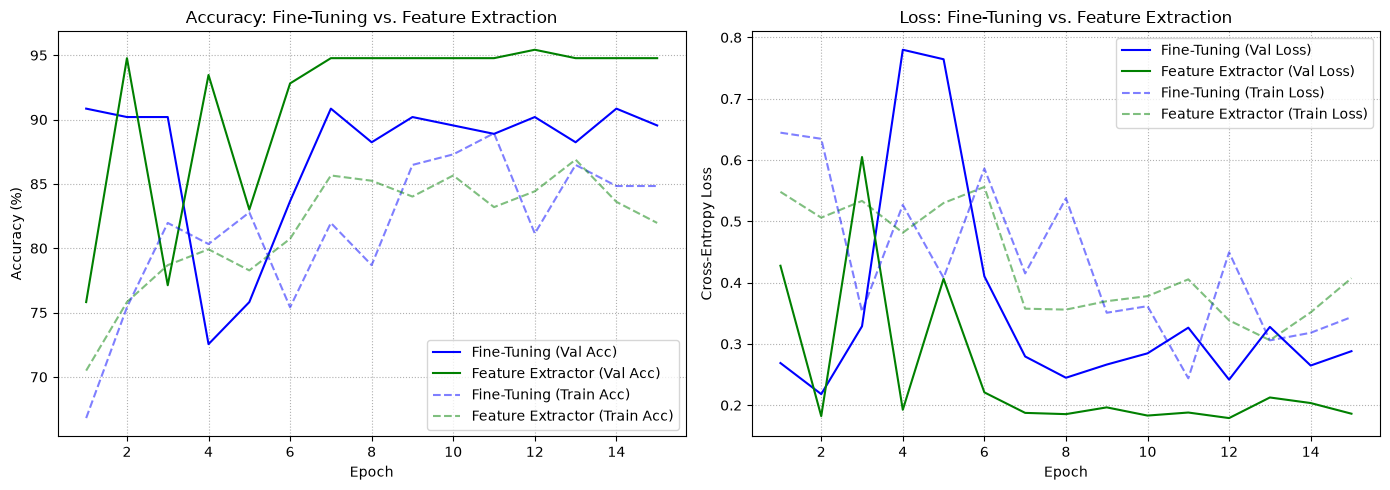

In [10]:
epochs_range = range(1, len(history_ft['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Validation & Training Accuracy comparison
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_ft['val_acc'], 'b-', label='Fine-Tuning (Val Acc)')
plt.plot(epochs_range, history_conv['val_acc'], 'g-', label='Feature Extractor (Val Acc)')
plt.plot(epochs_range, history_ft['train_acc'], 'b--', alpha=0.5, label='Fine-Tuning (Train Acc)')
plt.plot(epochs_range, history_conv['train_acc'], 'g--', alpha=0.5, label='Feature Extractor (Train Acc)')
plt.title('Accuracy: Fine-Tuning vs. Feature Extraction', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle=':')
plt.legend()

# Validation & Training Loss comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_ft['val_loss'], 'b-', label='Fine-Tuning (Val Loss)')
plt.plot(epochs_range, history_conv['val_loss'], 'g-', label='Feature Extractor (Val Loss)')
plt.plot(epochs_range, history_ft['train_loss'], 'b--', alpha=0.5, label='Fine-Tuning (Train Loss)')
plt.plot(epochs_range, history_conv['train_loss'], 'g--', alpha=0.5, label='Feature Extractor (Train Loss)')
plt.title('Loss: Fine-Tuning vs. Feature Extraction', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True, linestyle=':')
plt.legend()

plt.tight_layout()
plt.show()

### Visualising the Results

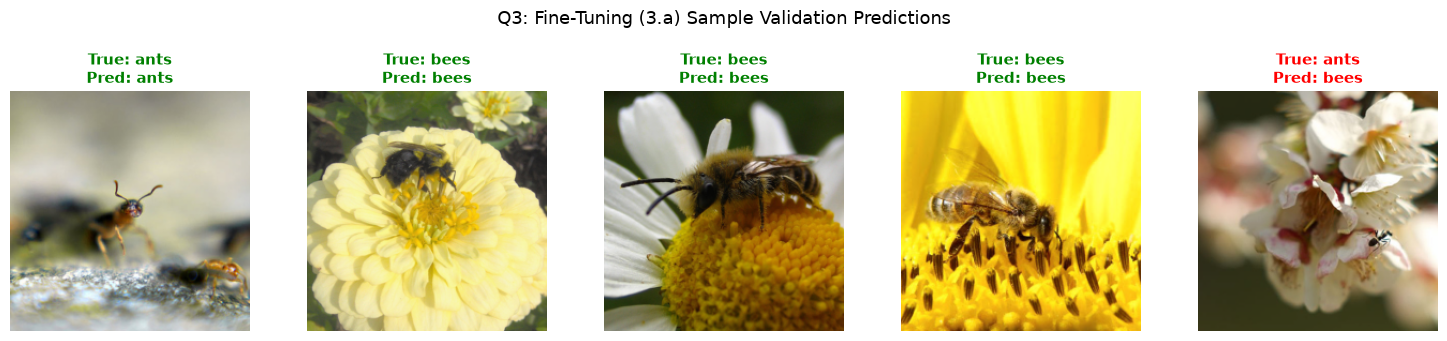

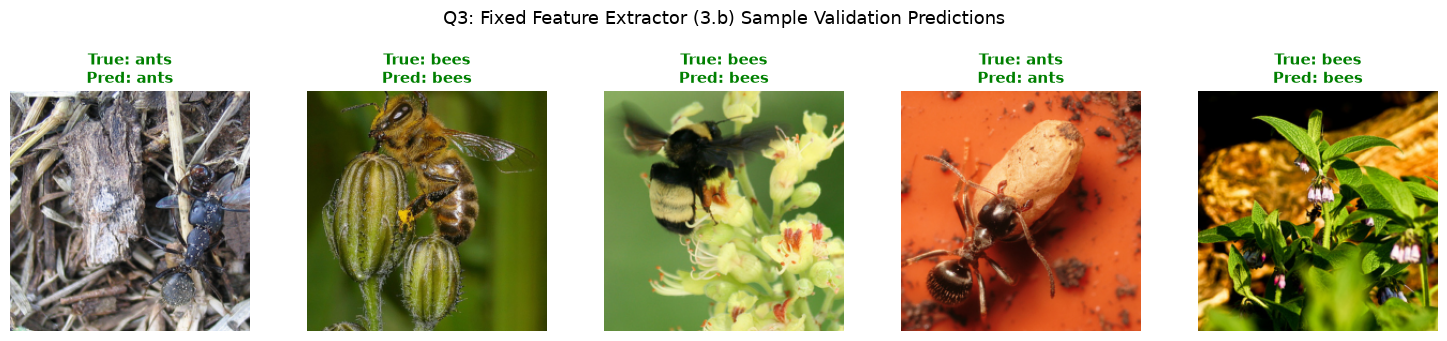

In [ ]:
def visualize_q3_horizontal(model, model_title="Model", num_images=5):
    was_training = model.training
    model.eval()
    
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    dataiter = iter(dataloaders['val'])
    inputs, labels = next(dataiter)

    if inputs.size(0) < num_images:
        inputs_2, labels_2 = next(dataiter)
        inputs = torch.cat([inputs, inputs_2], dim=0)
        labels = torch.cat([labels, labels_2], dim=0)

    inputs_dev = inputs[:num_images].to(device)
    labels_dev = labels[:num_images].to(device)
    with torch.no_grad():
        outputs = model(inputs_dev)
        _, preds = torch.max(outputs, 1)

    fig, axes = plt.subplots(1, num_images, figsize=(15, 3.2))

    for idx in range(num_images):
        ax = axes[idx]
        ax.axis('off')

        inp = inputs[idx].numpy().transpose((1, 2, 0))
        inp = std * inp + mean
        inp = np.clip(inp, 0, 1)

        is_correct = (preds[idx].cpu() == labels[idx])
        color = 'green' if is_correct else 'red'

        ax.set_title(
            f"True: {class_names[labels[idx]]}\nPred: {class_names[preds[idx]]}",
            color=color,
            fontsize=11,
            fontweight='bold'
        )
        ax.imshow(inp)

    plt.suptitle(f"Q3: {model_title}, fontsize=13, y=1.05)" )
    plt.tight_layout()
    plt.show()
    model.train(mode=was_training)

# Run for both Q3 models
visualize_q3_horizontal(model_ft, model_title="Fine-Tuning (3.a)", num_images=5)
visualize_q3_horizontal(model_conv, model_title="Fixed Feature Extractor (3.b)", num_images=5)

### Discussion
* Looking at the training and validation curves, the fixed feature extractor demonstrated much better stability and efficiency than full fine-tuning. Its loss curve glided smoothly downward to flatten near 0.19, allowing validation accuracy to climb reliably to a peak of 95.42% in just 4 minutes and 30 seconds.  
* In contrast, the fine-tuning plots reveal significant instability. The fine-tuning loss spiked sharply to 0.78 around epoch 4, which dragged accuracy down to 72.55% before it eventually recovered to a lower final best of 90.85% after 11 minutes and 45 seconds.  
* The sample predictions directly reflect the trends seen in the graphs. The fixed feature extractor correctly identified all five test examples across challenging settings  
* Fine-tuning classified the first four correctly but failed on the fifth image by predicting a bee instead of an ant.